# Choosing which measures to report

A results table usually lists several measures, and it is natural to ask whether they say different things.
A confusion matrix has few degrees of freedom, so the answer is often no: two for a binary problem, $m(m-1)$
for $m$ classes, $2m$ for $m$ labels. Remark 2 of the companion paper turns this into a test: a set of $k \le d$
measures is locally non-redundant if and only if the Jacobian of the measures with respect to the free
parameters of the confusion matrix has full row rank $k$.

`suite_rank` computes that Jacobian on your data and its rank. `select_suite` goes one step further and
picks the measures that span the most. That step is an addition of the package and not a result of the
paper: the rows of the Jacobian are scaled to unit length and the *information volume* of a suite is the
volume they span, which is 1 when the gradients are mutually orthogonal and 0 when the suite is redundant.
"Information" here means independence of the measures as functions of the confusion matrix, not a statistical
quantity. The Jacobian is also local: it is evaluated at the confusion matrix of the model and the data given.

In [1]:
# Installs the package only where it is missing (for example in Colab).
import importlib.util
if importlib.util.find_spec("aggmetrics") is None:
    %pip install -q aggmetrics scikit-learn matplotlib pandas

In [2]:
import io
import urllib.request
import warnings
warnings.filterwarnings("ignore")
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_predict
from sklearn.multioutput import MultiOutputClassifier

from aggmetrics import IndicatorMatrix, get_measure, list_measures, select_suite, suite_rank

BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "axes.edgecolor": INK2, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "lines.linewidth": 2, "font.size": 10, "figure.dpi": 100,
})

## Binary: the paper's basis comes out

Three-fold cross-validated logistic regression on the multilabel *yeast* data, and its most balanced label as
a binary problem.

In [3]:
URL = "https://raw.githubusercontent.com/rcprati/aggmetrics/main/examples/data/yeast.npz"
local = Path("../data/yeast.npz")
source = local if local.exists() else io.BytesIO(urllib.request.urlopen(URL, timeout=60).read())
with np.load(source) as z:
    X, Y = z["X"], z["Y"].astype(int)

pred = cross_val_predict(MultiOutputClassifier(LogisticRegression(max_iter=300)), X, Y, cv=3)
j = int(np.argmin(np.abs(Y.mean(axis=0) - 0.5)))              # the most balanced label
im_bin = IndicatorMatrix(Y[:, j], pred[:, j], task="binary")
print(f"label {j}: {int(Y[:, j].sum())} positives of {len(Y)}; (tp, fp, fn, tn) =", im_bin.counts)

label 1: 1038 positives of 2417; (tp, fp, fn, tn) = (463.0, 333.0, 575.0, 1046.0)


In [4]:
suites = {
    "recall, specificity": ["recall", "specificity"],
    "recall, false-negative rate": ["recall", "fnr"],
    "precision, recall": ["precision", "recall"],
    "accuracy, precision, recall, F1": ["label_accuracy", "precision", "recall", "f1"],
    "accuracy, precision, recall, F1, MCC, specificity": ["label_accuracy", "precision", "recall", "f1", "mcc", "specificity"],
}
rows = {}
for label, ms in suites.items():
    r = suite_rank(im_bin, ms, "micro")
    rows[label] = {"measures": len(ms), "rank": r.rank, "degrees of freedom": r.degrees_of_freedom,
                   "information volume": round(r.volume, 4), "redundant": r.redundant}
pd.DataFrame(rows).T

,measures,rank,degrees of freedom,information volume,redundant
"recall, specificity",2,2,2,1.0,False
"recall, false-negative rate",2,1,2,0.0,True
"precision, recall",2,2,2,0.8794,False
"accuracy, precision, recall, F1",4,2,2,0.0,True
"accuracy, precision, recall, F1, MCC, specificity",6,2,2,0.0,True


In [5]:
everything = select_suite(im_bin, aggregation="micro")
usual = select_suite(im_bin, [(m, "micro") for m in ("label_accuracy", "precision", "recall", "f1", "mcc")])
print("best pair among all 21 measures:", [m for m, _ in everything.items], "| volume", round(everything.volume, 4))
print("best pair among accuracy, precision, recall, F1, MCC:", [m for m, _ in usual.items], "| volume", round(usual.volume, 4))

best pair among all 21 measures: ['recall', 'specificity'] | volume 1.0
best pair among accuracy, precision, recall, F1, MCC: ['precision', 'recall'] | volume 0.8794


The rank test finds what the algebra says. Recall with the false-negative rate is rank 1 (one is one minus
the other). The four usual measures, accuracy, precision, recall and $F_1$, have rank 2 because the problem has
two degrees of freedom, so two of the four are functions of the other two at this model, and adding MCC and
specificity does not add a direction. Among all 21 measures the best pair is recall and specificity, which is
the basis of the paper, with volume 1. Restricted to accuracy, precision, recall, $F_1$ and MCC, it is precision
and recall, with volume 0.879: close to orthogonal, but not exactly.

## Ten classes: 90 degrees of freedom

The bundled CIFAR-10-LT predictions of notebook 06, a cross-entropy model and a logit-adjusted one, on the
CIFAR-10 test set (1000 images per class).

In [6]:
URL = "https://raw.githubusercontent.com/rcprati/aggmetrics/main/examples/data/cifar10lt/predictions.npz"
local = Path("../data/cifar10lt/predictions.npz")
source = local if local.exists() else io.BytesIO(urllib.request.urlopen(URL, timeout=60).read())
z = np.load(source)
loss, seed, y_test = z["loss"], z["seed"], z["y_test"].astype(int)

def run(name, s=0):
    i = int(np.flatnonzero((loss == name) & (seed == s))[0])
    return IndicatorMatrix(y_test, z["pred_test"][i].astype(int), task="multiclass", n_classes=10)

ce, adjusted = run("ce"), run("logit_adj")
print("classes:", ce.m, "| degrees of freedom m(m-1):", ce.degrees_of_freedom, "| accuracy:", round(ce.accuracy(), 4))

classes: 10 | degrees of freedom m(m-1): 90 | accuracy: 0.6498


In [7]:
usual = [("label_accuracy", "micro"), ("precision", "macro"), ("recall", "macro"),
         ("f1", "macro"), ("mcc", "macro"), ("balanced_accuracy", "macro")]
r = suite_rank(ce, usual)
print("six usual measures: rank", r.rank, "| singular values:", np.array2string(r.singular_values, precision=1))
for drop in usual:
    rest = [u for u in usual if u != drop]
    print(f"  without {drop[1]}-{drop[0]:18s} rank {suite_rank(ce, rest).rank}")
three = suite_rank(ce, [usual[0], usual[2], usual[5]])
print("micro accuracy, macro recall and macro balanced accuracy together: rank", three.rank)
print("macro-recall equals accuracy on this test set:", bool(np.isclose(ce.compute("recall", "macro"), ce.accuracy())),
      "| images per class:", np.bincount(y_test).min(), "to", np.bincount(y_test).max())

six usual measures: rank 4 | singular values: [2.4e+00 5.6e-01 2.1e-01 1.9e-02 5.1e-10 1.8e-10]
  without micro-label_accuracy     rank 4
  without macro-precision          rank 3
  without macro-recall             rank 4
  without macro-f1                 rank 3


  without macro-mcc                rank 3
  without macro-balanced_accuracy  rank 4
micro accuracy, macro recall and macro balanced accuracy together: rank 1


macro-recall equals accuracy on this test set: True | images per class: 1000 to 1000


Six measures that are usually reported together have rank 4. Three of them span a single direction: micro
accuracy, macro-recall and macro balanced accuracy have rank 1 together, and removing any one of them leaves
rank 4. The last line shows why for one pair: with the same number of images in every class, macro-recall is
accuracy. The rank test puts micro accuracy and macro balanced accuracy on that same direction. Dropping macro-precision, macro-$F_1$ or macro-MCC takes the rank to 3, so those each add a direction.

The confusion matrix has 90 directions, though. How many do aggregated measures span at all? Here, the 21
measures under each of the three operators that are functions of the confusion matrix (micro, macro and
weighted), 63 candidates.

In [8]:
candidates = [(m, op) for op in ("micro", "macro", "weighted") for m in list_measures()]
candidates.sort(key=lambda c: not get_measure(c[0]).greater_is_better)    # ties go to "greater is better"
everything = suite_rank(ce, candidates)
print(len(candidates), "candidates; rank", everything.rank, "of", everything.degrees_of_freedom, "degrees of freedom")
print("singular values 9 to 14:", np.array2string(everything.singular_values[8:14], precision=1))

63 candidates; rank 11 of 90 degrees of freedom
singular values 9 to 14: [1.7e-03 2.6e-04 1.1e-04 2.4e-08 4.1e-09 3.2e-09]


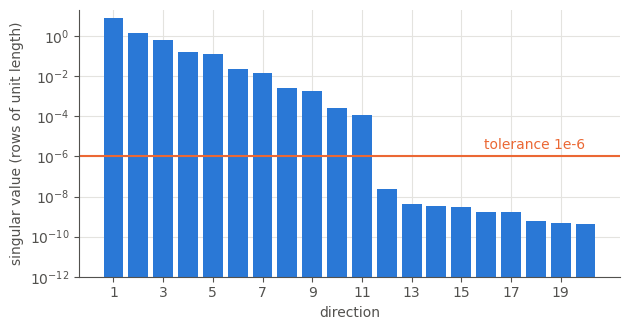

In [9]:
sv = everything.singular_values[:20]
fig, ax = plt.subplots(figsize=(6.4, 3.4))
ax.bar(range(1, len(sv) + 1), np.maximum(sv, 1e-12), color=BLUE)
ax.axhline(1e-6, color=ORANGE, linewidth=1.5)
ax.text(len(sv), 1.6e-6, "tolerance 1e-6", color=ORANGE, ha="right", va="bottom")
ax.set_yscale("log"); ax.set_ylim(1e-12, 20)
ax.set_xticks(range(1, len(sv) + 1, 2))
ax.set_xlabel("direction"); ax.set_ylabel("singular value (rows of unit length)")
plt.tight_layout(); plt.show()

The 63 candidates together have rank 11 of 90. The singular values drop from $1.1\times10^{-4}$ to
$2.4\times10^{-8}$ between the eleventh and the twelfth, so the rank does not depend on where in that gap the
tolerance sits. To first order, none of the 63 measures responds to movements along the other 79 directions,
which are combinations of the individual class-to-class confusion rates. To see those, read the confusion matrix or the per-class rates.

Within the 11 directions, the selection picks the suites below, for sizes 2 to 5.

In [10]:
rows = {}
for model_name, im in (("cross-entropy", ce), ("logit-adjusted", adjusted)):
    for k in (2, 3, 4, 5):
        s = select_suite(im, candidates, size=k)
        rows[(model_name, k)] = {"information volume": s.volume,
                                 "measures": ", ".join(f"{m} ({op[:3]})" for m, op in s.items)}
table = pd.DataFrame(rows).T
table["information volume"] = table["information volume"].astype(float).map(lambda v: f"{v:.4f}")
table

information volume  \
cross-entropy  2             0.6612   
               3             0.1809   
               4             0.0223   
               5             0.0024   
logit-adjusted 2             0.4399   
               3             0.0737   
               4             0.0059   
               5             0.0002   

                                                           measures  
cross-entropy  2                       precision (mac), gmean (wei)  
               3               precision (mac), f1 (wei), for (wei)  
               4  precision (mac), gmean (wei), for (wei), jacca...  
               5  precision (mac), gmean (wei), for (wei), jacca...  
logit-adjusted 2                       gmean (wei), precision (wei)  
               3               f1 (mac), precision (wei), for (wei)  
               4  gmean (wei), precision (wei), for (wei), jacca...  
               5  gmean (wei), precision (wei), for (wei), jacca...

The volume falls quickly with the size of the suite: for the cross-entropy model it is 0.661 for two
measures, 0.181 for three, 0.022 for four and 0.0024 for five, so the fifth measure adds a direction that
is almost parallel to the first four. The two models do not get the same suites: with three measures one gets
macro-precision, weighted $F_1$ and weighted false-omission rate, and the other macro-$F_1$, weighted precision
and the same rate, and the volumes differ (0.181 and 0.074). The Jacobian is local, so a suite chosen on one
model is not necessarily the best for another.

Remark 2 also recommends pairing a row-conditioned measure, such as macro-recall, with a column-conditioned
one, such as macro-precision, instead of two row-conditioned ones.

In [11]:
pair = suite_rank(ce, [("recall", "macro"), ("precision", "macro")])
twin = suite_rank(ce, [("recall", "macro"), ("fnr", "macro")])
print("macro-recall with macro-precision: rank", pair.rank, "| volume", round(pair.volume, 4))
print("macro-recall with macro-fnr      : rank", twin.rank, "| volume", round(twin.volume, 4))

macro-recall with macro-precision: rank 2 | volume 0.5991
macro-recall with macro-fnr      : rank 1 | volume 0.0


The pair has rank 2 and volume 0.599, and macro-recall with macro-false-negative rate has rank 1, which is
the same collinearity as in the binary case, now at ten classes.

## Multilabel

The same on the 14 labels of *yeast*, which have $2m = 28$ degrees of freedom.

In [12]:
im_ml = IndicatorMatrix(Y, pred, task="multilabel")
r = suite_rank(im_ml, candidates)
print("yeast:", im_ml.m, "labels; degrees of freedom", im_ml.degrees_of_freedom, "| the", len(candidates),
      "candidates have rank", r.rank)
s = select_suite(im_ml, candidates, size=5)
print("best five (volume %.4f):" % s.volume, ", ".join(f"{m} ({op[:3]})" for m, op in s.items))

yeast: 14 labels; degrees of freedom 28 | the 63 candidates have rank 24
best five (volume 0.6629): recall (mic), specificity (mic), gmean (mac), precision (wei), specificity (wei)


The 63 candidates have rank 24 of 28, much closer to the full space than in the ten-class case, presumably
because under macro and weighted averaging the values of the labels stay separate. The best five, by volume 0.663, are recall and specificity
under micro, macro G-mean, and weighted precision and specificity.

## Summary

- Many measures are redundant at a given model, and the rank of their Jacobian says how many are not. Six
  common ten-class measures have rank 4, and three of them are one direction when the classes have equal sizes.
- For a binary problem the best pair is recall and specificity, which is the basis of the paper. Among the
  measures a venue asks for, it is precision and recall.
- With more than two classes, aggregated measures span few directions: 11 of 90 at ten classes, 24 of 28 for
  14 labels. What aggregation hides is in the confusion matrix.
- The selection is local and depends on the model and the data. The information volume is a score of the
  package and not a result of the paper, and it says how close to redundant a suite is, not how useful the
  measures are for a decision. Cost-sensitive measures, which carry that, are in notebook 04.